In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "kagglehub", "scikit-learn", "matplotlib", "pillow", "tqdm", "pandas"
])
print("Dependencies are ready. If Colab asks to restart the runtime, restart it and continue from Cell 2.")

Dependencies are ready. If Colab asks to restart the runtime, restart it and continue from Cell 2.


In [ ]:
import os
import re
import json
import random
import shutil
import subprocess
import collections
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import vit_b_16, ViT_B_16_Weights
from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset, WeightedRandomSampler

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix, accuracy_score
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. Full ViT training on CPU will be very slow.")

PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
import kagglehub

try:
    plantvillage_download_path = kagglehub.dataset_download(
        "abdallahalidev/plantvillage-dataset"
    )
except Exception as exc:
    raise RuntimeError(
        "KaggleHub could not download PlantVillage. If the message indicates authentication is required, "
        "open https://www.kaggle.com/settings/api, generate a Kaggle API token, run `kagglehub.login()` "
        "in a separate cell, then rerun this cell. Original error: " + repr(exc)
    ) from exc

print("PlantVillage download path:", plantvillage_download_path)


def find_color_folder(root_path):
    root_path = Path(root_path)
    common_candidates = [
        root_path / "plantvillage dataset" / "color",
        root_path / "PlantVillage" / "color",
        root_path / "color",
    ]
    for candidate in common_candidates:
        if candidate.is_dir() and any(p.is_dir() for p in candidate.iterdir()):
            return candidate

    for current, directories, _ in os.walk(root_path):
        if Path(current).name.lower() == "color":
            if any((Path(current) / directory).is_dir() for directory in directories):
                return Path(current)
    raise FileNotFoundError(
        "Could not locate the PlantVillage 'color' folder. "
        "Inspect the downloaded path above and update color_data_path manually."
    )

color_data_path = str(find_color_folder(plantvillage_download_path))
print("Using PlantVillage color folder:", color_data_path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
PlantVillage download path: /kaggle/input/plantvillage-dataset
Using PlantVillage color folder: /kaggle/input/plantvillage-dataset/plantvillage dataset/color


In [ ]:
PLANTDOC_DIR = "/content/PlantDoc-Dataset"
PLANTDOC_REPO = "https://github.com/pratikkayal/PlantDoc-Dataset.git"

if not Path(PLANTDOC_DIR).exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", PLANTDOC_REPO, PLANTDOC_DIR],
        check=True
    )
else:
    print("PlantDoc directory already exists; reusing it.")

plantdoc_train_dir = Path(PLANTDOC_DIR) / "train"
plantdoc_test_dir = Path(PLANTDOC_DIR) / "test"
if not plantdoc_train_dir.is_dir() or not plantdoc_test_dir.is_dir():
    raise FileNotFoundError(
        "Expected PlantDoc train/ and test/ folders. Check the repository download."
    )

print("PlantDoc train folder:", plantdoc_train_dir)
print("PlantDoc test folder:", plantdoc_test_dir)
print("PlantDoc train categories:", sum(p.is_dir() for p in plantdoc_train_dir.iterdir()))
print("PlantDoc test categories:", sum(p.is_dir() for p in plantdoc_test_dir.iterdir()))

PlantDoc train folder: /content/PlantDoc-Dataset/train
PlantDoc test folder: /content/PlantDoc-Dataset/test
PlantDoc train categories: 28
PlantDoc test categories: 27


In [ ]:
# Read class names and labels from PlantVillage, without applying any transforms yet.
pv_index_dataset = ImageFolder(root=color_data_path)
class_names = list(pv_index_dataset.classes)
class_to_idx = dict(pv_index_dataset.class_to_idx)
num_classes = len(class_names)

print("Number of PlantVillage images:", len(pv_index_dataset))
print("Number of classes:", num_classes)
for i, name in enumerate(class_names):
    print(f"{i:2d}: {name}")

assert num_classes == 38, (
    f"Expected the 38-class PlantVillage setup, but found {num_classes}. "
    "Review the data path before continuing."
)

Number of PlantVillage images: 54305
Number of classes: 38
 0: Apple___Apple_scab
 1: Apple___Black_rot
 2: Apple___Cedar_apple_rust
 3: Apple___healthy
 4: Blueberry___healthy
 5: Cherry_(including_sour)___Powdery_mildew
 6: Cherry_(including_sour)___healthy
 7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8: Corn_(maize)___Common_rust_
 9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomat

In [ ]:
IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.15),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(
        brightness=0.18,
        contrast=0.18,
        saturation=0.15,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


def normalize_folder_name(name):
    """Normalize folder spelling/punctuation for lookup only."""
    return re.sub(r"[^a-z0-9]+", " ", name.lower()).strip()


# Keys are normalized PlantDoc folder names; values are EXACT existing PlantVillage labels.
# Ambiguous categories are intentionally not mapped.
PLANTDOC_FOLDER_TO_PV_LABEL = {
    "apple scab leaf": "Apple___Apple_scab",
    "apple leaf": "Apple___healthy",
    # "apple rust leaf" omitted: PlantVillage has the more specific cedar apple rust label.
    "bell pepper leaf": "Pepper,_bell___healthy",
    # "bell pepper leaf spot" omitted: not guaranteed to mean bacterial spot.
    "blueberry leaf": "Blueberry___healthy",
    "cherry leaf": "Cherry_(including_sour)___healthy",
    "corn gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    # "corn leaf blight" omitted: generic label is not guaranteed to mean northern leaf blight.
    "corn rust leaf": "Corn_(maize)___Common_rust_",
    "peach leaf": "Peach___healthy",
    "potato leaf early blight": "Potato___Early_blight",
    "potato leaf late blight": "Potato___Late_blight",
    "raspberry leaf": "Raspberry___healthy",
    "soyabean leaf": "Soybean___healthy",
    "squash powdery mildew leaf": "Squash___Powdery_mildew",
    "strawberry leaf": "Strawberry___healthy",
    "tomato early blight leaf": "Tomato___Early_blight",
    "tomato septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "tomato leaf late blight": "Tomato___Late_blight",
    "tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "tomato leaf": "Tomato___healthy",
    "tomato mold leaf": "Tomato___Leaf_Mold",
    "tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf black rot": "Grape___Black_rot",
    "grape leaf": "Grape___healthy",
}

# Check the mapping against the labels found in the downloaded PlantVillage data.
invalid_mappings = {
    folder: label
    for folder, label in PLANTDOC_FOLDER_TO_PV_LABEL.items()
    if label not in class_to_idx
}
if invalid_mappings:
    print("WARNING: These mappings are not present in PlantVillage and will be skipped:")
    print(invalid_mappings)
    PLANTDOC_FOLDER_TO_PV_LABEL = {
        folder: label for folder, label in PLANTDOC_FOLDER_TO_PV_LABEL.items()
        if label in class_to_idx
    }

print("PlantDoc categories with explicit mappings:", len(PLANTDOC_FOLDER_TO_PV_LABEL))

PlantDoc categories with explicit mappings: 25


In [ ]:
from collections import defaultdict

VALID_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def scan_plantdoc_split(split_dir):
    """Return records with only explicitly mapped labels; report skipped folder names."""
    split_dir = Path(split_dir)
    records = []
    skipped_folders = []
    corrupt_or_empty = 0

    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        normalized = normalize_folder_name(class_dir.name)
        pv_label = PLANTDOC_FOLDER_TO_PV_LABEL.get(normalized)
        if pv_label is None or pv_label not in class_to_idx:
            skipped_folders.append(class_dir.name)
            continue

        target = class_to_idx[pv_label]
        image_paths = sorted(
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS
        )
        for image_path in image_paths:
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupt_or_empty += 1
                continue
            records.append({
                "path": str(image_path),
                "label": int(target),
                "source_folder": class_dir.name,
                "domain": "plantdoc",
            })

    return records, sorted(set(skipped_folders)), corrupt_or_empty


plantdoc_train_all, skipped_train_folders, bad_train_images = scan_plantdoc_split(plantdoc_train_dir)
plantdoc_test_records, skipped_test_folders, bad_test_images = scan_plantdoc_split(plantdoc_test_dir)

if not plantdoc_train_all:
    raise RuntimeError(
        "No PlantDoc images were mapped to PlantVillage labels. "
        "Inspect the class folder names and update the explicit mapping in Cell 6."
    )
if not plantdoc_test_records:
    raise RuntimeError(
        "No PlantDoc test images were mapped. Inspect Cell 6 mapping before training."
    )

# Make a deterministic train/validation split per label. For very small classes,
# keep at least one training image; a class with one image has no field validation image.
rng = random.Random(SEED)
by_label = defaultdict(list)
for record in plantdoc_train_all:
    by_label[record["label"]].append(record)

plantdoc_train_records = []
plantdoc_val_records = []
for label, rows in sorted(by_label.items()):
    rows = rows.copy()
    rng.shuffle(rows)
    if len(rows) >= 2:
        val_count = max(1, int(round(0.15 * len(rows))))
        val_count = min(val_count, len(rows) - 1)
    else:
        val_count = 0
    plantdoc_val_records.extend(rows[:val_count])
    plantdoc_train_records.extend(rows[val_count:])

# Reproducible stratified PlantVillage split.
pv_targets = np.asarray(pv_index_dataset.targets)
pv_indices = np.arange(len(pv_index_dataset))
pv_train_indices, pv_val_indices = train_test_split(
    pv_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=pv_targets,
)

# Separate dataset instances are essential: each subset now has its own transform.
pv_train_base = ImageFolder(root=color_data_path, transform=train_transform)
pv_val_base = ImageFolder(root=color_data_path, transform=eval_transform)
assert pv_train_base.classes == pv_val_base.classes == class_names

pv_train_dataset = Subset(pv_train_base, pv_train_indices.tolist())
pv_val_dataset = Subset(pv_val_base, pv_val_indices.tolist())

print("PlantVillage train:", len(pv_train_dataset))
print("PlantVillage validation:", len(pv_val_dataset))
print("PlantDoc mapped train:", len(plantdoc_train_records))
print("PlantDoc mapped validation:", len(plantdoc_val_records))
print("PlantDoc mapped official test:", len(plantdoc_test_records))
print("PlantDoc skipped train categories:", skipped_train_folders)
print("PlantDoc skipped test categories:", skipped_test_folders)
print("Corrupt/unreadable images skipped:", bad_train_images + bad_test_images)

if len(plantdoc_val_records) == 0:
    raise RuntimeError("No PlantDoc validation images. Check mapped class counts in Cell 8.")

PlantVillage train: 43444
PlantVillage validation: 10861
PlantDoc mapped train: 1717
PlantDoc mapped validation: 304
PlantDoc mapped official test: 205
PlantDoc skipped train categories: ['Apple rust leaf', 'Bell_pepper leaf spot', 'Corn leaf blight']
PlantDoc skipped test categories: ['Apple rust leaf', 'Bell_pepper leaf spot', 'Corn leaf blight']
Corrupt/unreadable images skipped: 0


In [ ]:
class ImageRecordDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        with Image.open(record["path"]) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(record["label"])


plantdoc_train_dataset = ImageRecordDataset(plantdoc_train_records, train_transform)
plantdoc_val_dataset = ImageRecordDataset(plantdoc_val_records, eval_transform)
plantdoc_test_dataset = ImageRecordDataset(plantdoc_test_records, eval_transform)

combined_train_dataset = ConcatDataset([pv_train_dataset, plantdoc_train_dataset])

# Dataset labels in precisely the same order as ConcatDataset.
pv_train_labels = [int(pv_index_dataset.targets[i]) for i in pv_train_indices]
field_train_labels = [int(row["label"]) for row in plantdoc_train_records]


def weights_for_source(labels, source_probability):
    """Balance classes within one source while reserving its source probability."""
    counts = collections.Counter(labels)
    number_of_present_classes = len(counts)
    if not labels or number_of_present_classes == 0:
        return []
    return [
        source_probability / (number_of_present_classes * counts[label])
        for label in labels
    ]


PLANTVILLAGE_PROBABILITY = 0.80
PLANTDOC_PROBABILITY = 0.20
pv_sample_weights = weights_for_source(pv_train_labels, PLANTVILLAGE_PROBABILITY)
field_sample_weights = weights_for_source(field_train_labels, PLANTDOC_PROBABILITY)
sample_weights = torch.as_tensor(pv_sample_weights + field_sample_weights, dtype=torch.double)

SAMPLES_PER_EPOCH = min(20000, len(combined_train_dataset))
batch_size = 16  # Conservative ViT batch size for a Colab T4 GPU.
num_workers = 2

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=SAMPLES_PER_EPOCH,
    replacement=True,
    generator=torch.Generator().manual_seed(SEED),
)

data_loader_kwargs = {
    "num_workers": num_workers,
    "pin_memory": (device.type == "cuda"),
}
train_loader = DataLoader(
    combined_train_dataset,
    batch_size=batch_size,
    sampler=train_sampler,
    **data_loader_kwargs,
)
pv_val_loader = DataLoader(
    pv_val_dataset,
    batch_size=batch_size,
    shuffle=False,
    **data_loader_kwargs,
)
field_val_loader = DataLoader(
    plantdoc_val_dataset,
    batch_size=batch_size,
    shuffle=False,
    **data_loader_kwargs,
)
field_test_loader = DataLoader(
    plantdoc_test_dataset,
    batch_size=batch_size,
    shuffle=False,
    **data_loader_kwargs,
)

print("Combined train dataset size:", len(combined_train_dataset))
print("Samples drawn per epoch:", SAMPLES_PER_EPOCH)
print("Expected source mix: 80% PlantVillage / 20% PlantDoc")
print("Training batches per epoch:", len(train_loader))

Combined train dataset size: 45161
Samples drawn per epoch: 20000
Expected source mix: 80% PlantVillage / 20% PlantDoc
Training batches per epoch: 1250


In [ ]:
EXISTING_CHECKPOINT_PATH = "/content/best_plant_disease_vit.pth"
EXISTING_CLASSES_PATH = "/content/classes.json"

model = None
loaded_existing_checkpoint = False

if Path(EXISTING_CHECKPOINT_PATH).is_file() and Path(EXISTING_CLASSES_PATH).is_file():
    try:
        with open(EXISTING_CLASSES_PATH, "r", encoding="utf-8") as f:
            old_class_info = json.load(f)
        old_classes = old_class_info.get("classes", [])
        if old_classes == class_names:
            model = vit_b_16(weights=None)
            model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
            old_state = torch.load(
                EXISTING_CHECKPOINT_PATH,
                map_location="cpu",
                weights_only=True,
            )
            model.load_state_dict(old_state, strict=True)
            loaded_existing_checkpoint = True
            print("Loaded your existing PlantVillage-trained checkpoint.")
        else:
            print("Existing classes.json does not match this dataset. Ignoring old checkpoint.")
    except Exception as exc:
        print("Could not load old checkpoint; using ImageNet weights instead.")
        print("Reason:", repr(exc))

if model is None:
    model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    print("Loaded ImageNet-pretrained ViT-B/16; the disease classification head is new.")

model = model.to(device)
print("Model ready. Output classes:", num_classes)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 174MB/s]


Loaded ImageNet-pretrained ViT-B/16; the disease classification head is new.
Model ready. Output classes: 38


In [ ]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.03)

BACKBONE_LR = 1e-5 if loaded_existing_checkpoint else 2e-5
HEAD_LR = 5e-5
EPOCHS = 5
PATIENCE = 2
WEIGHT_DECAY = 1e-4
BEST_MODEL_PATH = "/content/best_plant_disease_vit.pth"

backbone_parameters = [
    parameter for name, parameter in model.named_parameters()
    if not name.startswith("heads.")
]
head_parameters = list(model.heads.parameters())
optimizer = optim.AdamW(
    [
        {"params": backbone_parameters, "lr": BACKBONE_LR},
        {"params": head_parameters, "lr": HEAD_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


def evaluate_model(model, loader, return_predictions=False):
    model.eval()
    total_loss = 0.0
    total = 0
    all_targets = []
    all_predictions = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, labels)
            predictions = logits.argmax(dim=1)
            total_loss += loss.item() * images.size(0)
            total += labels.size(0)
            all_targets.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())

    average_loss = total_loss / max(total, 1)
    accuracy = accuracy_score(all_targets, all_predictions) if total else 0.0
    if return_predictions:
        return average_loss, accuracy, all_targets, all_predictions
    return average_loss, accuracy

print(f"Backbone LR: {BACKBONE_LR:g} | Head LR: {HEAD_LR:g}")
print(f"Epochs: {EPOCHS} | Early-stopping patience: {PATIENCE}")

Backbone LR: 2e-05 | Head LR: 5e-05
Epochs: 5 | Early-stopping patience: 2


/tmp/ipykernel_638/703702321.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


In [ ]:
history = []
best_field_val_acc = -1.0
best_pv_val_acc_at_best_field = 0.0
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    total_train = 0
    correct_train = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS} [Train]")
    for images, labels in train_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size_now = images.size(0)
        running_loss += loss.item() * batch_size_now
        correct_train += (logits.argmax(dim=1) == labels).sum().item()
        total_train += batch_size_now
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / max(total_train, 1)
    train_acc = correct_train / max(total_train, 1)

    pv_val_loss, pv_val_acc = evaluate_model(model, pv_val_loader)
    field_val_loss, field_val_acc = evaluate_model(model, field_val_loader)
    scheduler.step()

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "plantvillage_val_loss": pv_val_loss,
        "plantvillage_val_accuracy": pv_val_acc,
        "plantdoc_val_loss": field_val_loss,
        "plantdoc_val_accuracy": field_val_acc,
    }
    history.append(row)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train       loss={train_loss:.4f}, accuracy={train_acc * 100:.2f}%")
    print(f"PlantVillage val loss={pv_val_loss:.4f}, accuracy={pv_val_acc * 100:.2f}%")
    print(f"PlantDoc val      loss={field_val_loss:.4f}, accuracy={field_val_acc * 100:.2f}%")

    # Select the checkpoint using field validation. PlantVillage accuracy is also reported,
    # but it is not the primary model-selection metric for real-world image generalization.
    if field_val_acc > best_field_val_acc:
        best_field_val_acc = field_val_acc
        best_pv_val_acc_at_best_field = pv_val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"Saved best checkpoint: {BEST_MODEL_PATH}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        print(f"No field-validation improvement ({epochs_without_improvement}/{PATIENCE}).")

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: field-validation accuracy did not improve.")
        break

if not Path(BEST_MODEL_PATH).is_file():
    raise FileNotFoundError("Training did not save a checkpoint. Check the logs above.")

# Always load the selected best checkpoint before evaluation/export.
best_state = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True)
model.load_state_dict(best_state, strict=True)
model.eval()
print("Best field-validation accuracy:", f"{best_field_val_acc * 100:.2f}%")

Epoch 1/5 [Train]:   0%|          | 0/1250 [00:00<?, ?it/s]

/tmp/ipykernel_638/2918875904.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_638/703702321.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_638/703702321.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):



Epoch 1/5
Train       loss=0.7643, accuracy=87.19%
PlantVillage val loss=0.3259, accuracy=97.48%
PlantDoc val      loss=1.2561, accuracy=65.79%
Saved best checkpoint: /content/best_plant_disease_vit.pth


Epoch 2/5 [Train]:   0%|          | 0/1250 [00:00<?, ?it/s]

/tmp/ipykernel_638/2918875904.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2519e19ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2519e19ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/util

...

/tmp/ipykernel_638/2918875904.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2519e19ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2519e19ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/util


Epoch 4/5
Train       loss=0.2754, accuracy=99.11%
PlantVillage val loss=0.2617, accuracy=99.40%
PlantDoc val      loss=1.3522, accuracy=67.76%
No field-validation improvement (1/2).


Epoch 5/5 [Train]:   0%|          | 0/1250 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2519e19ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2519e19ee0>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a


Epoch 5/5
Train       loss=0.2620, accuracy=99.48%
PlantVillage val loss=0.2563, accuracy=99.62%
PlantDoc val      loss=1.2818, accuracy=70.39%
No field-validation improvement (2/2).
Early stopping: field-validation accuracy did not improve.
Best field-validation accuracy: 70.72%


,epoch,train_loss,train_accuracy,plantvillage_val_loss,plantvillage_val_accuracy,plantdoc_val_loss,plantdoc_val_accuracy
0,1,0.764343,0.87185,0.325939,0.974772,1.256097,0.657895
1,2,0.370884,0.96225,0.278198,0.991529,1.286248,0.657895
2,3,0.309125,0.98060,0.278878,0.988399,1.227111,0.707237
3,4,0.275414,0.99105,0.261703,0.994015,1.352212,0.677632
4,5,0.262022,0.99475,0.256321,0.996225,1.281792,0.703947


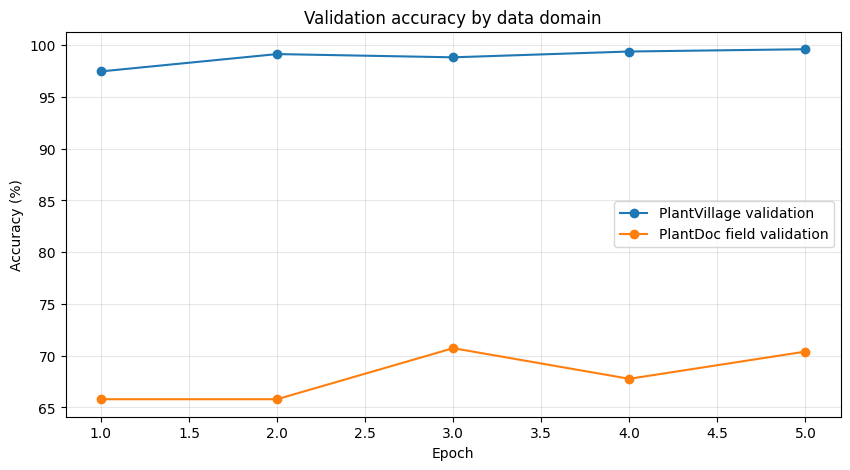

In [ ]:
import pandas as pd

history_df = pd.DataFrame(history)
display(history_df)

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["plantvillage_val_accuracy"] * 100, marker="o", label="PlantVillage validation")
plt.plot(history_df["epoch"], history_df["plantdoc_val_accuracy"] * 100, marker="o", label="PlantDoc field validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Validation accuracy by data domain")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

history_df.to_csv("/content/training_history.csv", index=False)

/tmp/ipykernel_638/703702321.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_638/703702321.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


PlantVillage validation accuracy: 98.84%
PlantDoc official test accuracy: 65.85%
PlantDoc official test loss: 1.1844

PlantDoc test classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.727     0.800     0.762        10
                                   Apple___healthy      0.636     0.778     0.700         9
                               Blueberry___healthy      0.545     0.545     0.545        11
                 Cherry_(including_sour)___healthy      0.600     0.300     0.400        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.750     0.750     0.750         4
                       Corn_(maize)___Common_rust_      1.000     0.900     0.947        10
                                 Grape___Black_rot      1.000     0.750     0.857         8
                                   Grape___healthy      0.857     1.000     0.923        12
                

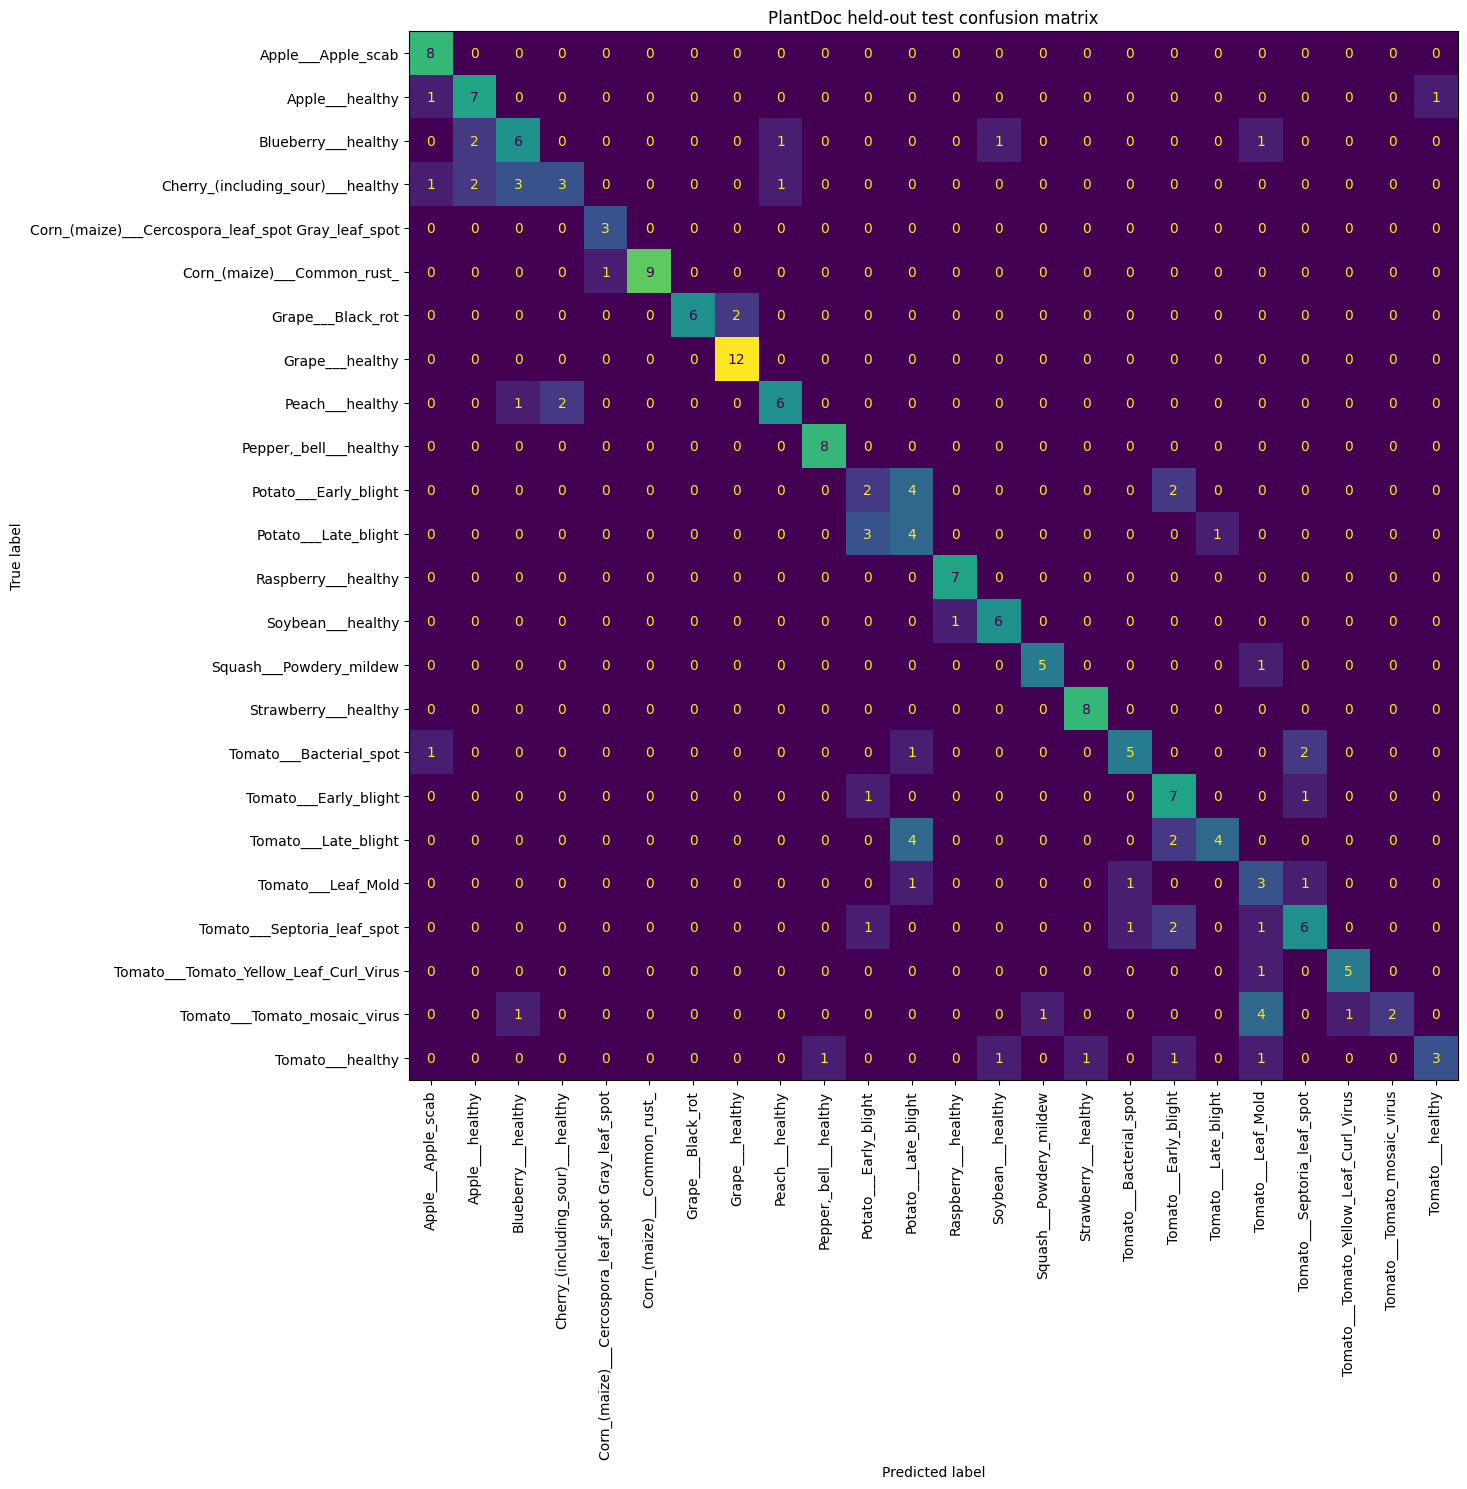

In [ ]:
pv_loss, pv_accuracy, pv_y_true, pv_y_pred = evaluate_model(
    model, pv_val_loader, return_predictions=True
)
field_loss, field_accuracy, field_y_true, field_y_pred = evaluate_model(
    model, field_test_loader, return_predictions=True
)

print("PlantVillage validation accuracy:", f"{pv_accuracy * 100:.2f}%")
print("PlantDoc official test accuracy:", f"{field_accuracy * 100:.2f}%")
print("PlantDoc official test loss:", f"{field_loss:.4f}")

present_labels = sorted(set(field_y_true))
print("\nPlantDoc test classification report:")
print(classification_report(
    field_y_true,
    field_y_pred,
    labels=present_labels,
    target_names=[class_names[i] for i in present_labels],
    zero_division=0,
    digits=3,
))

cm = confusion_matrix(field_y_true, field_y_pred, labels=present_labels)
fig_size = max(10, min(22, int(len(present_labels) * 0.65)))
fig, ax = plt.subplots(figsize=(fig_size, fig_size))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[class_names[i] for i in present_labels],
)
display.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
plt.title("PlantDoc held-out test confusion matrix")
plt.tight_layout()
plt.show()

Saving cercospora-leaf3.webp to cercospora-leaf3.webp


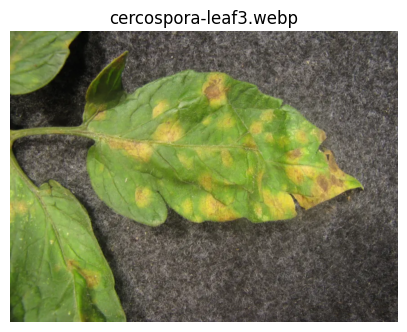

Top predictions for cercospora-leaf3.webp:
  Tomato___Leaf_Mold: 98.50%
  Potato___Early_blight: 0.22%
  Tomato___Septoria_leaf_spot: 0.16%
  Pepper,_bell___Bacterial_spot: 0.10%
  Peach___Bacterial_spot: 0.06%
Reminder: high confidence does not guarantee the disease label is correct.



/tmp/ipykernel_638/281492441.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


In [ ]:
from google.colab import files

uploaded = files.upload()


def predict_image_pil(image, top_k=5):
    image = image.convert("RGB")
    tensor = eval_transform(image).unsqueeze(0).to(device)
    model.eval()
    with torch.inference_mode():
        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            logits = model(tensor)
            probabilities = torch.softmax(logits, dim=1)[0]
    top_values, top_indices = torch.topk(probabilities, k=min(top_k, num_classes))
    return [
        (class_names[index], float(value))
        for value, index in zip(top_values.cpu().tolist(), top_indices.cpu().tolist())
    ]

for filename, content in uploaded.items():
    try:
        with Image.open(filename) as img:
            image = img.convert("RGB")
        plt.figure(figsize=(5, 5))
        plt.imshow(image)
        plt.axis("off")
        plt.title(filename)
        plt.show()
        print(f"Top predictions for {filename}:")
        for label, probability in predict_image_pil(image, top_k=5):
            print(f"  {label}: {probability * 100:.2f}%")
        print("Reminder: high confidence does not guarantee the disease label is correct.\n")
    except Exception as exc:
        print(f"Could not predict {filename}: {exc}")

In [ ]:
export_dir = Path("/content/plant_disease_deployment_package")
export_dir.mkdir(parents=True, exist_ok=True)

# Save the selected best state dictionary in the plain format expected by torchvision load_state_dict.
torch.save(model.state_dict(), export_dir / "best_plant_disease_vit.pth")

class_mapping = {
    "classes": class_names,
    "id2label": {str(index): label for index, label in enumerate(class_names)},
    "label2id": {label: index for index, label in enumerate(class_names)},
}
with open(export_dir / "classes.json", "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, indent=2)

preprocessing_config = {
    "architecture": "torchvision.models.vit_b_16",
    "image_size": IMAGE_SIZE,
    "color_mode": "RGB",
    "mean": IMAGENET_MEAN,
    "std": IMAGENET_STD,
    "num_classes": len(class_names),
    "selection_metric": "PlantDoc validation accuracy",
    "plantvillage_validation_accuracy": float(pv_accuracy),
    "plantdoc_official_test_accuracy": float(field_accuracy),
    "note": "Confidence is not a guarantee. Evaluate on locally collected, correctly labelled field images.",
}
with open(export_dir / "model_config.json", "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, indent=2)

readme_text = """Plant disease ViT deployment package\n\nFiles:\n- best_plant_disease_vit.pth: torchvision ViT-B/16 state_dict\n- classes.json: exact output class order used during training\n- model_config.json: preprocessing and evaluation metadata\n\nBackend compatibility:\nUse torchvision.models.vit_b_16, replace model.heads.head with Linear(768, 38),\nload best_plant_disease_vit.pth with model.load_state_dict(..., strict=True),\nand use RGB + Resize((224,224)) + ImageNet mean/std normalization.\nDo not load this .pth file with transformers.AutoModelForImageClassification.\n\nValidation note:\nPlantVillage accuracy and PlantDoc accuracy measure different image domains.\nThe model may still be wrong on photos unlike the data used here.\n"""
(export_dir / "README.txt").write_text(readme_text, encoding="utf-8")

zip_path = shutil.make_archive(
    "/content/plant_disease_deployment_package",
    "zip",
    root_dir=str(export_dir),
)
print("Created:", zip_path)
print("Package contents:", [p.name for p in export_dir.iterdir()])

from google.colab import files
files.download(zip_path)

Created: /content/plant_disease_deployment_package.zip
Package contents: ['model_config.json', 'classes.json', 'best_plant_disease_vit.pth', 'README.txt']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>